# Capstone Mini-Project: Image Classifier with Transfer Learning

On an offline CIFAR-10 subset: visualise the data, train a small CNN **from scratch** as a baseline, then beat it with **transfer learning** (MobileNetV2 feature extraction, then fine-tuning) plus data augmentation and early-stopping callbacks. Finish with a confusion matrix, per-class scores, a Grad-CAM interpretation and an honest baseline-vs-transfer analysis.

Everything is tuned to run on CPU in a few minutes. CIFAR-10 is read from the local Keras cache.

## Prerequisites: load a small, class-balanced CIFAR-10 subset

In [1]:
import numpy as np, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

RNG = 42
np.random.seed(RNG); tf.random.set_seed(RNG)

# Reads from the local ~/.keras/datasets cache - no network needed once it is cached.
(x_train_full, y_train_full), (x_test_full, y_test_full) = keras.datasets.cifar10.load_data()

CLASSES = ["airplane","automobile","bird","cat","deer","dog",
           "frog","horse","ship","truck"]

def subset(x, y, per_class):
    y = y.ravel()
    idx = np.hstack([np.random.RandomState(RNG).choice(np.where(y==c)[0], per_class, replace=False)
                     for c in range(10)])
    np.random.RandomState(RNG).shuffle(idx)
    return x[idx].astype("float32")/255.0, y[idx].astype("int32")

# small, balanced subset keeps CPU training to minutes
x_train, y_train = subset(x_train_full, y_train_full, 500)   # 5000 imgs
x_test,  y_test  = subset(x_test_full,  y_test_full,  100)   # 1000 imgs
print(x_train.shape, x_test.shape, "range", x_train.min(), x_train.max())

(5000, 32, 32, 3) (1000, 32, 32, 3) range 0.0 1.0


## Step 1: Load and visualise the data
Never train blind: plot a labelled grid and confirm the classes are balanced.

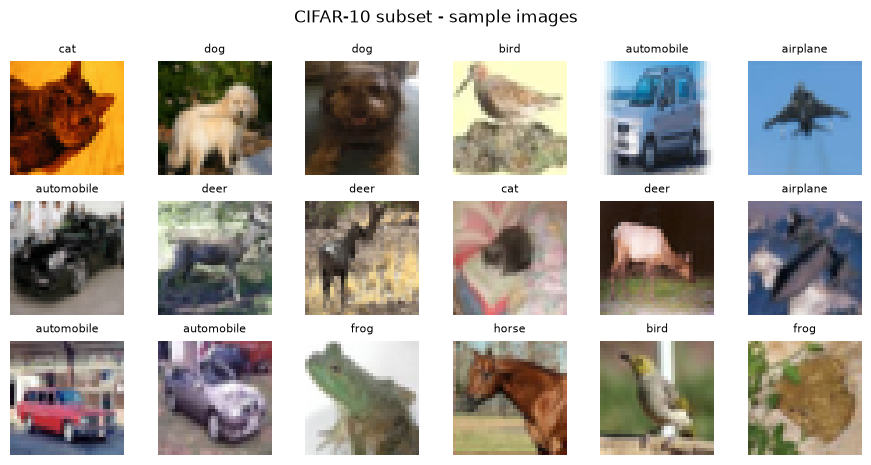

airplane     500
automobile   500
bird         500
cat          500
deer         500
dog          500
frog         500
horse        500
ship         500
truck        500


In [2]:
fig, axes = plt.subplots(3, 6, figsize=(9, 4.7))
for ax, i in zip(axes.ravel(), range(18)):
    ax.imshow(x_train[i]); ax.set_title(CLASSES[y_train[i]], fontsize=8)
    ax.axis("off")
plt.suptitle("CIFAR-10 subset - sample images"); plt.tight_layout(); plt.show()

counts = np.bincount(y_train, minlength=10)
for c, n in enumerate(counts):
    print(f"{CLASSES[c]:12s} {n}")

## Step 2: Baseline, a small CNN from scratch
This is the number to beat: three conv blocks, batch-norm, global average pooling, dropout and a 10-way softmax, with no pretrained weights. `EarlyStopping` halts training when validation accuracy stalls.

In [3]:
def make_baseline_cnn():
    m = keras.Sequential([
        keras.Input((32,32,3)),
        layers.Conv2D(32,3,padding="same",activation="relu"), layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(64,3,padding="same",activation="relu"), layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(128,3,padding="same",activation="relu"), layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax"),
    ])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

baseline = make_baseline_cnn()
es = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4,
                                   restore_best_weights=True)
hist_base = baseline.fit(x_train, y_train, validation_split=0.2,
                         epochs=25, batch_size=64, callbacks=[es], verbose=2)
base_test = baseline.evaluate(x_test, y_test, verbose=0)[1]
print(f"\nBASELINE test accuracy = {base_test:.3f}")

Epoch 1/25


63/63 - 2s - 24ms/step - accuracy: 0.3343 - loss: 1.8311 - val_accuracy: 0.1490 - val_loss: 2.4243


Epoch 2/25


63/63 - 1s - 15ms/step - accuracy: 0.4363 - loss: 1.5448 - val_accuracy: 0.1290 - val_loss: 2.8504


Epoch 3/25


63/63 - 1s - 15ms/step - accuracy: 0.4950 - loss: 1.4206 - val_accuracy: 0.1640 - val_loss: 3.3714


... (41 outputs left out)

63/63 - 1s - 16ms/step - accuracy: 0.8975 - loss: 0.3809 - val_accuracy: 0.5160 - val_loss: 1.5347


Epoch 25/25


63/63 - 1s - 16ms/step - accuracy: 0.9115 - loss: 0.3446 - val_accuracy: 0.5040 - val_loss: 1.5409



BASELINE test accuracy = 0.528


## Step 3: Data augmentation
More effective data without more images: random flips, small rotations and small zooms teach invariances that regularise training. They are only active during training.

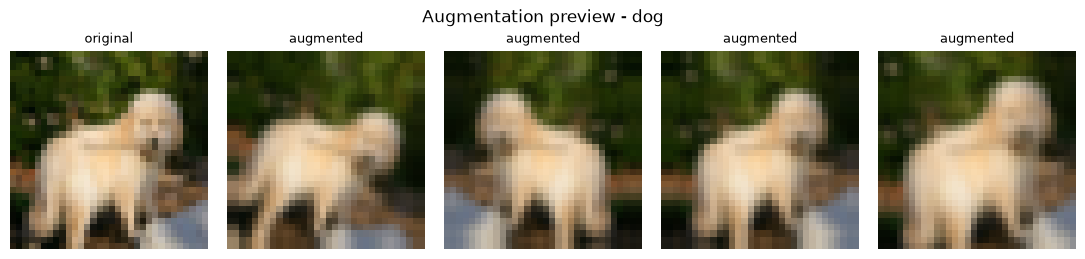

In [4]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.1),
], name="augment")

img = x_train[1][None, ...]
fig, axes = plt.subplots(1, 5, figsize=(11, 2.6))
axes[0].imshow(img[0]); axes[0].set_title("original", fontsize=9); axes[0].axis("off")
for ax in axes[1:]:
    ax.imshow(np.clip(data_augmentation(img, training=True)[0], 0, 1))
    ax.set_title("augmented", fontsize=9); ax.axis("off")
plt.suptitle(f"Augmentation preview - {CLASSES[y_train[1]]}"); plt.tight_layout(); plt.show()

## Step 4: Transfer learning, part A: feature extraction
MobileNetV2 pretrained on ImageNet with the classifier head removed and the backbone **frozen**; only a fresh 10-way head is trained. The 32x32 images are resized to 96x96 and MobileNet's own `preprocess_input` is applied inside the model.

In [5]:
IMG = 96
base = keras.applications.MobileNetV2(input_shape=(IMG,IMG,3),
                                      include_top=False, weights="imagenet")
base.trainable = False                      # freeze - feature extraction only

inputs = keras.Input((32,32,3))
x = data_augmentation(inputs)
x = layers.Resizing(IMG, IMG)(x)
x = layers.Rescaling(255.0)(x)                              # [0,1] -> [0,255]
x = keras.applications.mobilenet_v2.preprocess_input(x)     # -> [-1,1]
x = base(x, training=False)                                 # frozen backbone
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)
tl_model = keras.Model(inputs, outputs)
tl_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print(f"trainable params (head only): {sum(np.prod(w.shape) for w in tl_model.trainable_weights):,}")

ckpt = keras.callbacks.ModelCheckpoint("day20_best.keras", monitor="val_accuracy",
                                       save_best_only=True)
es2 = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                    restore_best_weights=True)
hist_fe = tl_model.fit(x_train, y_train, validation_split=0.2,
                       epochs=8, batch_size=64, callbacks=[es2, ckpt], verbose=2)
fe_test = tl_model.evaluate(x_test, y_test, verbose=0)[1]
print(f"\nFEATURE-EXTRACTION test accuracy = {fe_test:.3f}")

trainable params (head only): 12,810
Epoch 1/8


63/63 - 5s - 73ms/step - accuracy: 0.4035 - loss: 1.8036 - val_accuracy: 0.7030 - val_loss: 0.8953


Epoch 2/8


63/63 - 3s - 52ms/step - accuracy: 0.5980 - loss: 1.1842 - val_accuracy: 0.7590 - val_loss: 0.7362


Epoch 3/8


63/63 - 4s - 56ms/step - accuracy: 0.6578 - loss: 1.0147 - val_accuracy: 0.7960 - val_loss: 0.6331


... (7 outputs left out)

63/63 - 3s - 51ms/step - accuracy: 0.7172 - loss: 0.8255 - val_accuracy: 0.8020 - val_loss: 0.5948


Epoch 8/8


63/63 - 3s - 53ms/step - accuracy: 0.7385 - loss: 0.7959 - val_accuracy: 0.8070 - val_loss: 0.5734



FEATURE-EXTRACTION test accuracy = 0.798


## Step 5: Transfer learning, part B: fine-tuning
Unfreeze only the last ~30 layers of the backbone and train gently with a learning rate 100x smaller, so the pretrained weights are nudged rather than smashed.

In [6]:
base.trainable = True
for layer in base.layers[:-30]:             # keep the lower, generic layers frozen
    layer.trainable = False

tl_model.compile(optimizer=keras.optimizers.Adam(1e-5),     # 100x smaller LR
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])

es3 = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                    restore_best_weights=True)
hist_ft = tl_model.fit(x_train, y_train, validation_split=0.2,
                       epochs=6, batch_size=64, callbacks=[es3, ckpt], verbose=2)
ft_test = tl_model.evaluate(x_test, y_test, verbose=0)[1]
print(f"\nFINE-TUNED test accuracy = {ft_test:.3f}")
print(f"baseline={base_test:.3f}  feat-extract={fe_test:.3f}  fine-tuned={ft_test:.3f}")

Epoch 1/6


63/63 - 7s - 108ms/step - accuracy: 0.6053 - loss: 1.1827 - val_accuracy: 0.8150 - val_loss: 0.5762


Epoch 2/6


63/63 - 5s - 72ms/step - accuracy: 0.6568 - loss: 1.0209 - val_accuracy: 0.8130 - val_loss: 0.5897


Epoch 3/6


63/63 - 5s - 72ms/step - accuracy: 0.6900 - loss: 0.9323 - val_accuracy: 0.8100 - val_loss: 0.6031


... (3 outputs left out)

63/63 - 5s - 75ms/step - accuracy: 0.7168 - loss: 0.8311 - val_accuracy: 0.8150 - val_loss: 0.6048


Epoch 6/6


63/63 - 5s - 78ms/step - accuracy: 0.7343 - loss: 0.7879 - val_accuracy: 0.8230 - val_loss: 0.5988



FINE-TUNED test accuracy = 0.799
baseline=0.528  feat-extract=0.798  fine-tuned=0.799


## Step 6: Evaluate, confusion matrix and per-class scores
One accuracy number hides where the model fails, so we build the confusion matrix and a per-class precision/recall report on the held-out test set.

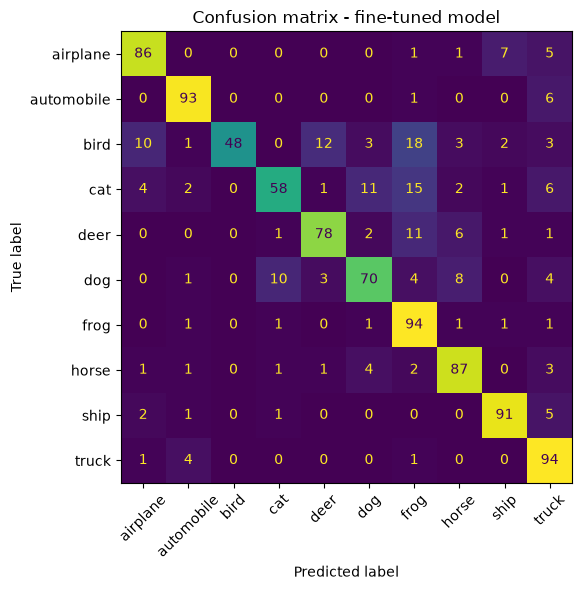

              precision    recall  f1-score   support

    airplane      0.827     0.860     0.843       100
  automobile      0.894     0.930     0.912       100
        bird      1.000     0.480     0.649       100
         cat      0.806     0.580     0.674       100
        deer      0.821     0.780     0.800       100
         dog      0.769     0.700     0.733       100
        frog      0.639     0.940     0.761       100
       horse      0.806     0.870     0.837       100
        ship      0.883     0.910     0.897       100
       truck      0.734     0.940     0.825       100

    accuracy                          0.799      1000
   macro avg      0.818     0.799     0.793      1000
weighted avg      0.818     0.799     0.793      1000



In [7]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_prob = tl_model.predict(x_test, verbose=0)
y_pred = y_prob.argmax(axis=1)

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6.5, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Confusion matrix - fine-tuned model"); plt.tight_layout(); plt.show()

print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

## Step 7: Interpret a prediction with Grad-CAM
Accuracy tells us *whether* the model is right; Grad-CAM shows *where* it looks. The backbone output is the last convolutional feature map, so a model from the input to `[backbone output, prediction]` gives Grad-CAM in a few lines. In Keras 3 the nested backbone's own `.output` is not connected to the outer model's input, so the feature map is taken from the *input of the pooling layer* (a tensor in the outer graph), which keeps the gradient model connected.

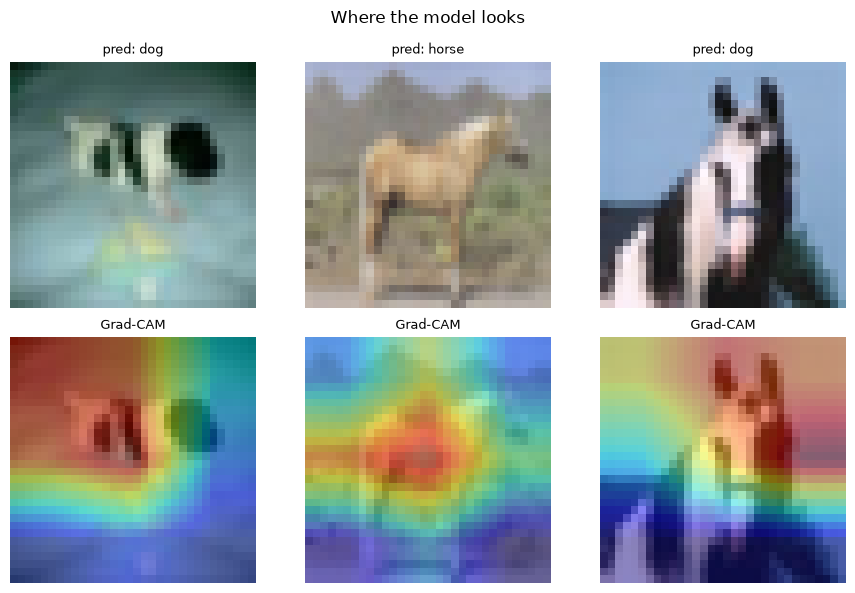

In [8]:
# the backbone's output is the INPUT of the global-average-pooling layer in the outer model's graph
gap_layer = [l for l in tl_model.layers if isinstance(l, layers.GlobalAveragePooling2D)][0]
grad_model = keras.Model(tl_model.inputs, [gap_layer.input, tl_model.output])

def gradcam(img_1, pred_index=None):
    arr = tf.convert_to_tensor(img_1[None, ...])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(arr)
        pred_index = int(tf.argmax(preds[0])) if pred_index is None else pred_index
        channel = preds[:, pred_index]
    grads = tape.gradient(channel, conv_out)
    weights = tf.reduce_mean(grads, axis=(0,1,2))
    cam = tf.maximum(tf.reduce_sum(conv_out[0] * weights, axis=-1), 0)
    cam = (cam / (tf.reduce_max(cam) + 1e-8)).numpy()
    return cam, pred_index

correct = np.where(y_pred == y_test)[0]
show = correct[:3]
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for col, i in enumerate(show):
    cam, pidx = gradcam(x_test[i])
    cam_up = tf.image.resize(cam[..., None], (32,32)).numpy().squeeze()
    axes[0,col].imshow(x_test[i]); axes[0,col].axis("off")
    axes[0,col].set_title(f"pred: {CLASSES[pidx]}", fontsize=9)
    axes[1,col].imshow(x_test[i]); axes[1,col].imshow(cam_up, cmap="jet", alpha=0.45)
    axes[1,col].axis("off"); axes[1,col].set_title("Grad-CAM", fontsize=9)
plt.suptitle("Where the model looks"); plt.tight_layout(); plt.show()

## Step 8: Written analysis, baseline vs transfer
The summary cell prints the numbers the reflection below cites.

In [9]:
print("=== RESULTS SUMMARY ===")
print(f"{'approach':22s}{'test acc':>10s}")
for name, acc in [("Baseline CNN (scratch)", base_test),
                  ("Transfer: feat-extract", fe_test),
                  ("Transfer: fine-tuned",   ft_test)]:
    print(f"{name:22s}{acc:10.3f}")
print(f"\nabsolute lift (fine-tuned - baseline) = {ft_test - base_test:+.3f}")

# save the finished model artefact
tl_model.save("day20_best.keras")
print("Saved best model -> day20_best.keras")

=== RESULTS SUMMARY ===
approach                test acc
Baseline CNN (scratch)     0.528
Transfer: feat-extract     0.798
Transfer: fine-tuned       0.799

absolute lift (fine-tuned - baseline) = +0.271
Saved best model -> day20_best.keras


### Reflection

| Approach | Test accuracy (1,000 images) |
| --- | ---: |
| Baseline CNN (from scratch) | 0.528 |
| Transfer: feature extraction (frozen MobileNetV2) | 0.798 |
| Transfer: fine-tuned (top ~30 layers, LR 1e-5) | 0.799 |

Absolute lift of fine-tuned over baseline: **+0.271**. This is a single run with one seed on a 1,000-image test set, so differences of about 0.02 or less are within noise.

**1. How much did transfer learning beat the baseline, and why?** By 27 points (0.528 to 0.799). The from-scratch CNN has to learn what edges, textures and shapes are from only 4,000 tiny 32x32 training images (5,000 minus the 20% validation split), and its validation accuracy was very noisy from epoch to epoch (it jumped between 0.13 and 0.56). MobileNetV2 arrives having already learned those building blocks from ImageNet, so a head of only 12,810 trainable parameters is enough to reach about 0.80. Our baseline also came out lower than the typical range in the brief (0.58 to 0.68), probably because early stopping on such a noisy validation score stopped it before it had settled, so the true gap is likely somewhat smaller than 27 points.

**2. What did feature extraction and fine-tuning each contribute?** Feature extraction gave essentially all of the gain (0.528 to 0.798). Fine-tuning added only 0.001 (0.798 to 0.799), which is no real improvement: with a very small learning rate, at most 6 epochs and 4,000 images there was little to adapt. Fine-tuning did not hurt, which is what we want at that learning rate, but on this data it was not worth the extra training time.

**3. Which classes were hardest, and does Grad-CAM agree?** Bird was the hardest (recall 0.48), then cat (0.58) and dog (0.70). The biggest confusions were bird predicted as frog (18 times), cat as frog (15), bird as deer (12), and cat and dog mixed with each other (11 and 10). Frog has recall 0.94 but precision only 0.64, so the model uses "frog" as a catch-all for small, low-resolution animals on a green or brown background. Grad-CAM on three *correctly* classified images put the heat on the animal's body or head for the horse and for the second dog, which is reassuring, but for the first dog part of the heat also covers the background, so a background cue may be involved. Three correct examples cannot prove the frog bias, so the next step would be to look at Grad-CAM on the bird-called-frog mistakes.

**4. What would I try next?** First, more fine-tuning budget: unfreeze more layers and train for more epochs with a somewhat larger learning rate (about 1e-4), since 1e-5 barely moved the weights. Second, a larger input than 96x96, because 32x32 images upscaled lose detail that ImageNet features expect. Third, more training images per class. I would not expect a different backbone to matter as much as these.

**Caveats.** Results are from one run and one seed. The 1,000 test images are a class-balanced subset of the CIFAR-10 test set. The model file `day20_best.keras` is regenerated by running the notebook and is not committed.